# RQ1 Step 5: Pooled VAR(1) velocity model

This notebook estimates one first-order vector autoregression from all continuous, training-only velocity transitions. Starting from each forecast-origin velocity, it recursively forecasts 72 future velocities and integrates them into positions.


## 1. Model definition

The next east/north velocity vector is a linear function of an intercept and the current two-component velocity. All training drifters share one coefficient matrix. This pooling avoids fitting an unstable time-series model from only 24 observations per case.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find data/processed; open the notebook from the project directory or a notebook subdirectory.')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'en'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6_371.0
HORIZON_HOURS = 72
SECONDS_PER_HOUR = 3_600.0
METRES_PER_KM = 1_000.0
N_FOLDS = 5

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Project directory: ', PROJECT_ROOT.resolve())
print('Output directory: ', OUTPUT_DIR.resolve())

Project directory:  /Users/roger/Documents/data3001-project-main
Output directory:  /Users/roger/Documents/data3001-project-main/output/rq1/en


## 2. Spherical position conversion and error function

Forecast velocities are integrated into local east/north displacement, converted to latitude/longitude and evaluated with Haversine separation error.


In [2]:
def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east_km = np.asarray(east_km, dtype=float)
    north_km = np.asarray(north_km, dtype=float)
    distance_km = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular_distance = distance_km / EARTH_RADIUS_KM
    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular_distance)
        + np.cos(lat0) * np.sin(angular_distance) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance) * np.cos(lat0),
        np.cos(angular_distance) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180.0) % 360.0 - 180.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

## 3. Read fixed partitions and construct training-only transitions

Only unique observations from the 364 training drifters are used. Consecutive hourly pairs are constructed within each continuous trajectory segment; overlapping forecast windows are not duplicated.


In [3]:
origins = (
    pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
    .sort_values('forecast_case_id').reset_index(drop=True)
)
drifter_splits = pd.read_csv(PROCESSED / 'drifter_splits.csv')
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude', 've', 'vn'],
).sort_values(['ID', 'segment_id', 'segment_step']).reset_index(drop=True)

train_indices = np.flatnonzero(origins['partition'].eq('training').to_numpy())
calibration_indices = np.flatnonzero(origins['partition'].eq('calibration').to_numpy())
test_indices = np.flatnonzero(origins['partition'].eq('test').to_numpy())
training_ids = set(drifter_splits.loc[drifter_splits['partition'].eq('training'), 'ID'])

training_observations = observations[observations['ID'].isin(training_ids)].copy()
grouped = training_observations.groupby(['ID', 'segment_id'], sort=False)
training_observations['next_step'] = grouped['segment_step'].shift(-1)
training_observations['next_ve'] = grouped['ve'].shift(-1)
training_observations['next_vn'] = grouped['vn'].shift(-1)
transitions = training_observations[
    training_observations['next_step'].eq(training_observations['segment_step'] + 1)
].dropna(subset=['ve', 'vn', 'next_ve', 'next_vn']).copy()

partition_summary = pd.DataFrame({
    'Item': [
        'Training cases', 'Calibration cases', 'Test cases',
        'Training drifters used by VAR', 'Unique training observations',
        'Consecutive one-hour transitions',
    ],
    'Count': [
        len(train_indices), len(calibration_indices), len(test_indices),
        len(training_ids), len(training_observations), len(transitions),
    ],
})
display(partition_summary)

assert len(train_indices) == 3591
assert len(calibration_indices) == 769
assert len(test_indices) == 757
assert len(training_ids) == 364
assert set(transitions['ID']).issubset(training_ids)
assert np.isfinite(transitions[['ve', 'vn', 'next_ve', 'next_vn']]).all().all()

,Item,Count
0,Training cases,3591
1,Calibration cases,769
2,Test cases,757
3,Training drifters used by VAR,364
4,Unique training observations,392533
5,Consecutive one-hour transitions,391204


## 4. Fit pooled VAR(1)

Ordinary least squares estimates the intercept and 2-by-2 transition matrix. Eigenvalues and spectral radius are reported to verify that recursive forecasts remain stable.


In [4]:
def fit_var1(transition_frame):
    design = np.column_stack([
        np.ones(len(transition_frame)),
        transition_frame['ve'].to_numpy(),
        transition_frame['vn'].to_numpy(),
    ])
    target = transition_frame[['next_ve', 'next_vn']].to_numpy()
    coefficients, _, _, _ = np.linalg.lstsq(design, target, rcond=None)
    return coefficients


def predict_next_velocity(coefficients, velocity):
    velocity = np.asarray(velocity, dtype=float)
    design = np.column_stack([np.ones(len(velocity)), velocity])
    return design @ coefficients


var_coefficients = fit_var1(transitions)
intercept = var_coefficients[0]
transition_matrix = np.array([
    [var_coefficients[1, 0], var_coefficients[2, 0]],
    [var_coefficients[1, 1], var_coefficients[2, 1]],
])
eigenvalues = np.linalg.eigvals(transition_matrix)
spectral_radius = float(np.max(np.abs(eigenvalues)))

coefficient_table = pd.DataFrame(
    var_coefficients,
    index=['Intercept', 'Current ve', 'Current vn'],
    columns=['Next ve', 'Next vn'],
)
display(coefficient_table.round(6))
print('VAR transition matrix eigenvalues：', np.round(eigenvalues, 6))
print(f'Spectral radius：{spectral_radius:.6f}')
print('Stability assessment: ', 'stable; recursive forecasts do not explode' if spectral_radius < 1 else 'unstable; revision required')
assert spectral_radius < 1, 'VAR(1) recursion is unstable.'

,Next ve,Next vn
Intercept,0.001203,0.004382
Current ve,0.949485,-0.014394
Current vn,0.045074,0.971846


VAR transition matrix eigenvalues： [0.960665+0.022887j 0.960665-0.022887j]
Spectral radius：0.960938
Stability assessment:  stable; recursive forecasts do not explode


## 5. Five-fold diagnostics within training drifters

Because VAR(1) has no selected order or tuning parameter here, grouped folds are diagnostic rather than model-selection folds. They assess one-step velocity prediction on unseen training drifters.


In [5]:
training_group_counts = transitions.groupby('ID').size().sort_values(ascending=False)
fold_drifters = [[] for _ in range(N_FOLDS)]
fold_transition_counts = np.zeros(N_FOLDS, dtype=int)
for drifter_id, count in training_group_counts.items():
    fold = int(np.argmin(fold_transition_counts))
    fold_drifters[fold].append(drifter_id)
    fold_transition_counts[fold] += int(count)

cv_rows = []
for fold_number, validation_drifters in enumerate(fold_drifters, start=1):
    is_validation = transitions['ID'].isin(validation_drifters)
    fold_train = transitions.loc[~is_validation]
    fold_valid = transitions.loc[is_validation]
    fold_coefficients = fit_var1(fold_train)
    prediction = predict_next_velocity(
        fold_coefficients, fold_valid[['ve', 'vn']].to_numpy()
    )
    truth = fold_valid[['next_ve', 'next_vn']].to_numpy()
    component_rmse = np.sqrt(np.mean(np.square(prediction - truth), axis=0))
    vector_rmse = np.sqrt(np.mean(np.sum(np.square(prediction - truth), axis=1)))
    cv_rows.append({
        'fold': fold_number,
        'validation_drifters': len(validation_drifters),
        'validation_cases': int(origins.loc[
            origins['partition'].eq('training') & origins['ID'].isin(validation_drifters)
        ].shape[0]),
        'validation_transitions': len(fold_valid),
        've_rmse_m_s': component_rmse[0],
        'vn_rmse_m_s': component_rmse[1],
        'vector_velocity_rmse_m_s': vector_rmse,
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
display(cv_results[['ve_rmse_m_s', 'vn_rmse_m_s', 'vector_velocity_rmse_m_s']].agg(['mean', 'std']).round(4))

,fold,validation_drifters,validation_cases,validation_transitions,ve_rmse_m_s,vn_rmse_m_s,vector_velocity_rmse_m_s
0,1,72,708,78241,0.0972,0.0871,0.1305
1,2,71,725,78241,0.1000,0.0889,0.1338
2,3,73,728,78241,0.0965,0.0837,0.1277
3,4,74,724,78241,0.0997,0.0878,0.1329
4,5,73,706,78240,0.1006,0.0909,0.1356


,ve_rmse_m_s,vn_rmse_m_s,vector_velocity_rmse_m_s
mean,0.0988,0.0877,0.1321
std,0.0019,0.0026,0.0031


## 6. Recursively forecast 72 velocities and integrate positions

Each test case begins at its forecast-origin velocity. VAR predicts the next velocity, converts it to a one-hour displacement, updates cumulative position and repeats for 72 hours.


In [6]:
def forecast_var1_displacements(coefficients, initial_velocity, horizon=HORIZON_HOURS):
    velocity = np.asarray(initial_velocity, dtype=float).copy()
    east_km = np.zeros((len(velocity), horizon))
    north_km = np.zeros((len(velocity), horizon))
    cumulative_east = np.zeros(len(velocity))
    cumulative_north = np.zeros(len(velocity))

    for lead_index in range(horizon):
        velocity = predict_next_velocity(coefficients, velocity)
        cumulative_east += velocity[:, 0] * SECONDS_PER_HOUR / METRES_PER_KM
        cumulative_north += velocity[:, 1] * SECONDS_PER_HOUR / METRES_PER_KM
        east_km[:, lead_index] = cumulative_east
        north_km[:, lead_index] = cumulative_north
    return east_km, north_km


test_origins = origins.loc[test_indices].reset_index(drop=True)
initial_velocity = test_origins[['origin_ve', 'origin_vn']].to_numpy()
predicted_east_km, predicted_north_km = forecast_var1_displacements(
    var_coefficients, initial_velocity
)

origin_latitudes = np.repeat(test_origins['origin_latitude'].to_numpy(), HORIZON_HOURS)
origin_longitudes = np.repeat(test_origins['origin_longitude'].to_numpy(), HORIZON_HOURS)
predicted_latitude, predicted_longitude = local_km_to_latlon(
    origin_latitudes, origin_longitudes,
    predicted_east_km.reshape(-1), predicted_north_km.reshape(-1),
)

display(pd.DataFrame({
    'forecast_case_id': test_origins['forecast_case_id'].head(),
    'origin_ve': initial_velocity[:5, 0],
    'origin_vn': initial_velocity[:5, 1],
    'predicted_ve_at_1h': predict_next_velocity(var_coefficients, initial_velocity[:5])[:, 0],
    'predicted_vn_at_1h': predict_next_velocity(var_coefficients, initial_velocity[:5])[:, 1],
    'predicted_east_at_72h_km': predicted_east_km[:5, -1],
    'predicted_north_at_72h_km': predicted_north_km[:5, -1],
}).round(4))

,forecast_case_id,origin_ve,origin_vn,predicted_ve_at_1h,predicted_vn_at_1h,predicted_east_at_72h_km,predicted_north_at_72h_km
0,80,0.0213,0.0628,0.0243,0.0651,21.8973,24.5616
1,81,-0.1213,0.2086,-0.1046,0.2089,25.2788,40.2768
2,82,0.2518,0.0642,0.2432,0.0631,33.4588,19.3941
3,83,-0.1904,-0.0694,-0.1827,-0.0603,1.8760,18.1337
4,84,0.4306,-0.3398,0.3947,-0.3320,13.3324,-19.1896


## 7. Read observed futures and calculate Haversine error

Predicted positions are aligned with the fixed observed future positions. No case is resampled and calibration remains unused.


In [7]:
targets = test_origins[[
    'forecast_case_id', 'ID', 'segment_id', 'target_start_step',
]].loc[test_origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets['lead_time_hours'] = np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins))
targets['segment_step'] = targets['target_start_step'] + targets['lead_time_hours'] - 1
targets = targets.merge(
    observations[['ID', 'segment_id', 'segment_step', 'latitude', 'longitude']],
    on=['ID', 'segment_id', 'segment_step'], how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'lead_time_hours']).reset_index(drop=True)

evaluation = pd.DataFrame({
    'forecast_case_id': np.repeat(test_origins['forecast_case_id'].to_numpy(), HORIZON_HOURS),
    'ID': np.repeat(test_origins['ID'].to_numpy(), HORIZON_HOURS),
    'lead_time_hours': np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
    'origin_latitude': origin_latitudes,
    'origin_longitude': origin_longitudes,
    'predicted_east_km': predicted_east_km.reshape(-1),
    'predicted_north_km': predicted_north_km.reshape(-1),
    'pred_latitude': predicted_latitude,
    'pred_longitude': predicted_longitude,
    'true_latitude': targets['latitude'].to_numpy(),
    'true_longitude': targets['longitude'].to_numpy(),
})
evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)

checks = pd.Series({
    'Evaluate only 757 test cases': evaluation['forecast_case_id'].nunique() == 757,
    'Every test case has exactly 72 lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
    'All observed positions matched successfully': evaluation[['true_latitude', 'true_longitude']].notna().all().all(),
    'All errors are finite': np.isfinite(evaluation['separation_error_km']).all(),
    'Calibration cases were not used for fitting': len(calibration_indices) == 769,
}, name='Passed')
display(checks.to_frame())
assert checks.all()

,Passed
Evaluate only 757 test cases,True
Every test case has exactly 72 lead times,True
All observed positions matched successfully,True
All errors are finite,True
Calibration cases were not used for fitting,True


## 8. Held-out test error by lead time

Report median, mean, interquartile range and RMSE across the 757 test cases.


,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,0.15,0.27,0.09,0.29,0.47
5,6,757,2.75,3.37,1.67,4.42,4.24
11,12,757,7.05,8.33,4.24,11.02,10.17
23,24,757,16.00,18.69,9.63,24.84,22.49
47,48,757,36.27,42.04,21.86,56.35,50.55
71,72,757,55.89,64.99,33.60,87.83,77.89


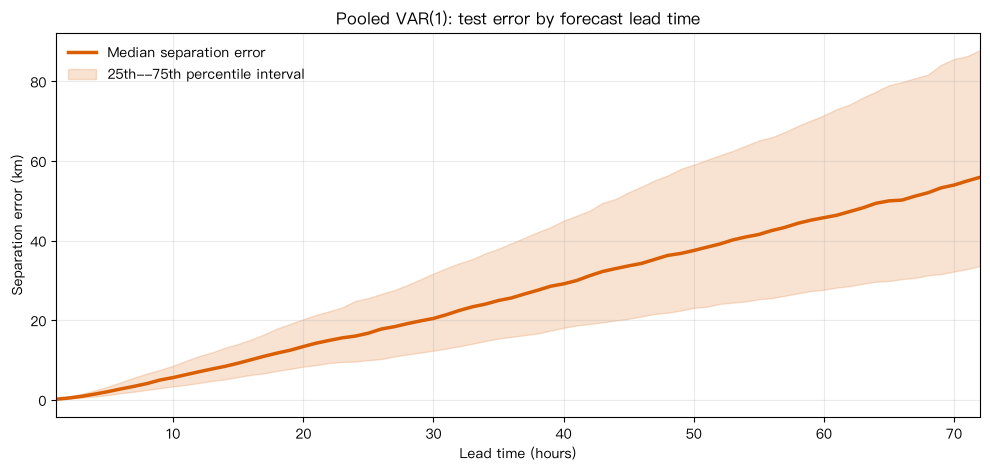

In [8]:
lead_metrics = (
    evaluation.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size', median_error_km='median', mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    ).reset_index()
)
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#d95f02', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#d95f02', alpha=0.18, label='25th--75th percentile interval')
ax.set(
    xlabel='Lead time (hours)', ylabel='Separation error (km)',
    title='Pooled VAR(1): test error by forecast lead time',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'var1_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 9. Fair comparison with FNN, Ridge and both baselines

The comparison uses the same cases and error definition. Positive skill means VAR(1) has lower RMSE than the reference method.


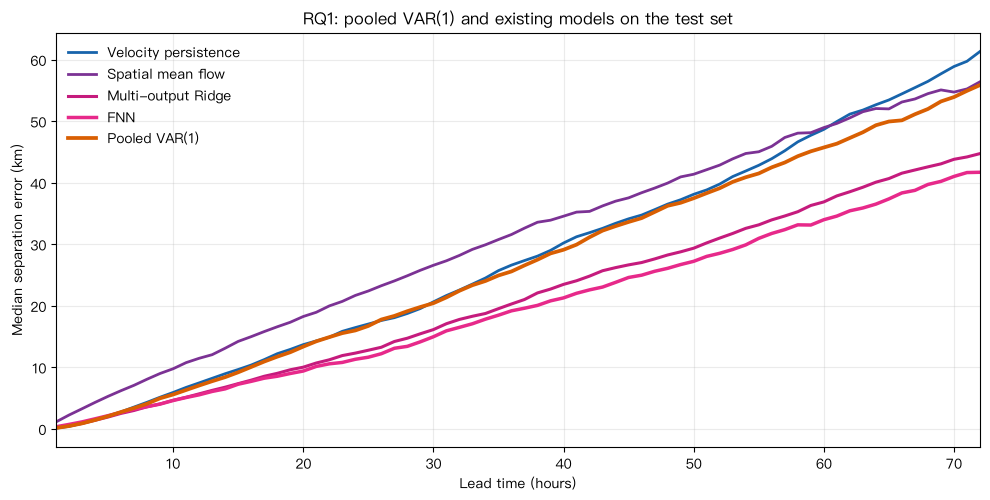

,var1_median_km,fnn_median_km,ridge_median_km,persistence_median_km,mean_flow_median_km,var1_rmse_km,fnn_rmse_km,ridge_rmse_km,persistence_rmse_km,mean_flow_rmse_km,var1_rmse_minus_persistence_km,skill_vs_persistence_pct,skill_vs_fnn_pct
lead_time_hours,,,,,,,,,,,,,
24,16.00,11.32,12.32,16.47,21.69,22.49,18.15,18.97,24.07,29.87,-1.58,6.57,-23.88
48,36.27,26.10,28.27,36.54,39.96,50.55,40.21,42.59,55.17,57.27,-4.62,8.37,-25.72
72,55.89,41.72,44.75,61.35,56.42,77.89,62.15,65.91,90.10,80.98,-12.22,13.56,-25.32


In [9]:
reference_files = {
    'persistence': 'velocity_persistence_lead_metrics.csv',
    'mean_flow': 'spatial_mean_flow_lead_metrics.csv',
    'ridge': 'ridge_lead_metrics.csv',
    'fnn': 'fnn_lead_metrics.csv',
}
comparison = lead_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
    'median_error_km': 'var1_median_km', 'rmse_km': 'var1_rmse_km',
})
for name, filename in reference_files.items():
    frame = pd.read_csv(OUTPUT_DIR / filename)
    comparison = comparison.merge(
        frame[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': f'{name}_median_km', 'rmse_km': f'{name}_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
    comparison[f'var1_rmse_minus_{name}_km'] = comparison['var1_rmse_km'] - comparison[f'{name}_rmse_km']
    comparison[f'skill_vs_{name}_pct'] = 100 * (1 - comparison['var1_rmse_km'] / comparison[f'{name}_rmse_km'])

fig, ax = plt.subplots(figsize=(10, 5.1))
for column, label, color, width in [
    ('persistence_median_km', 'Velocity persistence', '#1764ab', 2.0),
    ('mean_flow_median_km', 'Spatial mean flow', '#7b3294', 2.0),
    ('ridge_median_km', 'Multi-output Ridge', '#c51b7d', 2.2),
    ('fnn_median_km', 'FNN', '#e7298a', 2.5),
    ('var1_median_km', 'Pooled VAR(1)', '#d95f02', 2.7),
]:
    ax.plot(comparison['lead_time_hours'], comparison[column], linewidth=width, color=color, label=label)
ax.set(
    xlabel='Lead time (hours)', ylabel='Median separation error (km)',
    title='RQ1: pooled VAR(1) and existing models on the test set',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'rq1_five_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

comparison_table = comparison.loc[
    comparison['lead_time_hours'].isin([24, 48, 72]),
    [
        'lead_time_hours',
        'var1_median_km', 'fnn_median_km', 'ridge_median_km',
        'persistence_median_km', 'mean_flow_median_km',
        'var1_rmse_km', 'fnn_rmse_km', 'ridge_rmse_km',
        'persistence_rmse_km', 'mean_flow_rmse_km',
        'var1_rmse_minus_persistence_km', 'skill_vs_persistence_pct',
        'skill_vs_fnn_pct',
    ],
].set_index('lead_time_hours')
display(comparison_table.round(2))

## 10. Case-level integrated trajectory error and summary

ITE measures accumulated error over the full 72-hour trajectory.


In [10]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = evaluation.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    'Metric': [
        'Training drifters', 'Training transitions', 'Calibration cases (unused)', 'Test cases',
        'Spectral radius', '24h median error (km)', '48h median error (km)',
        '72h median error (km)', '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    'Value': [
        len(training_ids), len(transitions), len(calibration_indices), len(test_indices),
        spectral_radius, metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary.round(4))

,Metric,Value
0,Training drifters,364.0000
1,Training transitions,391204.0000
2,Calibration cases (unused),769.0000
3,Test cases,757.0000
4,Spectral radius,0.9609
5,24h median error (km),16.0045
6,48h median error (km),36.2656
7,72h median error (km),55.8918
8,72h RMSE (km),77.8857
9,Median ITE (km·h),1894.7754


## 11. Representative test trajectory

The example has a 72-hour endpoint error closest to the VAR(1) test median.


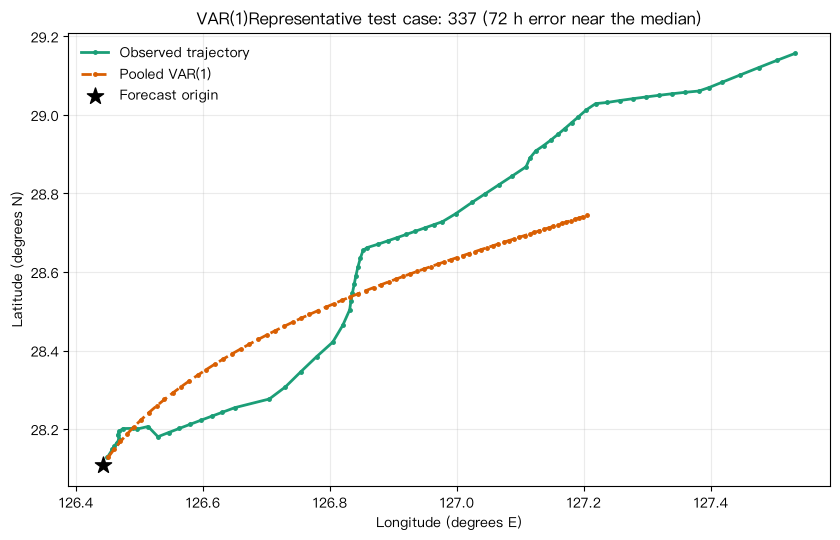

In [11]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example = evaluation[evaluation['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
        linewidth=2, color='#1b9e77', label='Observed trajectory')
ax.plot(example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
        linewidth=2, color='#d95f02', label='Pooled VAR(1)')
ax.scatter(example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
           marker='*', s=150, color='black', label='Forecast origin', zorder=5)
ax.set(
    xlabel='Longitude (degrees E)', ylabel='Latitude (degrees N)',
    title=f'VAR(1)Representative test case: {int(example_id)} (72 h error near the median)',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'var1_example_trajectory.png', dpi=200, bbox_inches='tight')
plt.show()

## 12. Save reproducible results

Save fitted coefficients, grouped diagnostics, held-out metrics, comparisons and figures.


In [12]:
cv_results.to_csv(OUTPUT_DIR / 'var1_grouped_cv_diagnostics.csv', index=False)
lead_metrics.to_csv(OUTPUT_DIR / 'var1_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'var1_test_case_metrics.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'rq1_five_model_comparison.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'var1_summary.csv', index=False)
np.savez_compressed(
    OUTPUT_DIR / 'var1_model_parameters.npz',
    coefficients=var_coefficients,
    intercept=intercept,
    transition_matrix=transition_matrix,
    eigenvalues=eigenvalues,
)

saved_files = sorted(
    [p.name for p in OUTPUT_DIR.glob('var1_*')]
    + [p.name for p in OUTPUT_DIR.glob('rq1_five_model_*')]
)
print('Saved:')
for name in saved_files:
    print(' -', name)

Saved:
 - rq1_five_model_comparison.csv
 - rq1_five_model_comparison.png
 - var1_error_curve.png
 - var1_example_trajectory.png
 - var1_grouped_cv_diagnostics.csv
 - var1_lead_metrics.csv
 - var1_model_parameters.npz
 - var1_summary.csv
 - var1_test_case_metrics.csv
